SEATTLE 911 CAD DATA - PRIORITY CLASSIFICATION MODEL

[STEP 1] Loading Seattle 911 CAD Data...
✓ Loaded 354,781 records
✓ Columns: ['CAD Event Number', 'CAD Event Clearance Description', 'Call Type', 'Priority', 'Initial Call Type', 'Final Call Type', 'CAD Event Original Time Queued', 'CAD Event Arrived Time', 'Dispatch Precinct', 'Dispatch Sector', 'Dispatch Beat', 'Dispatch Longitude', 'Dispatch Latitude', 'Dispatch Reporting Area', 'CAD Event Response Category', 'Call Sign Dispatch ID', 'Call Sign Dispatch Time', 'First CARE Call Sign At Scene Time', 'First CARE Call Sign Dispatch Time', 'First Co-Response Call Sign At Scene Time', 'First Co-Response Call Sign Dispatch Time', 'First SPD Call Sign at Scene Time', 'First SPD Call Sign Dispatch Time', 'Last CARE Call Sign In-Service Time', 'Last Co-Response Call Sign In-Service Time', 'Last SPD Call Sign In-Service Time', 'CARE Call Sign Total Service Time (s)', 'Co-Response Call Sign Total Service Time (s)', 'SPD Call Sign Total Servi

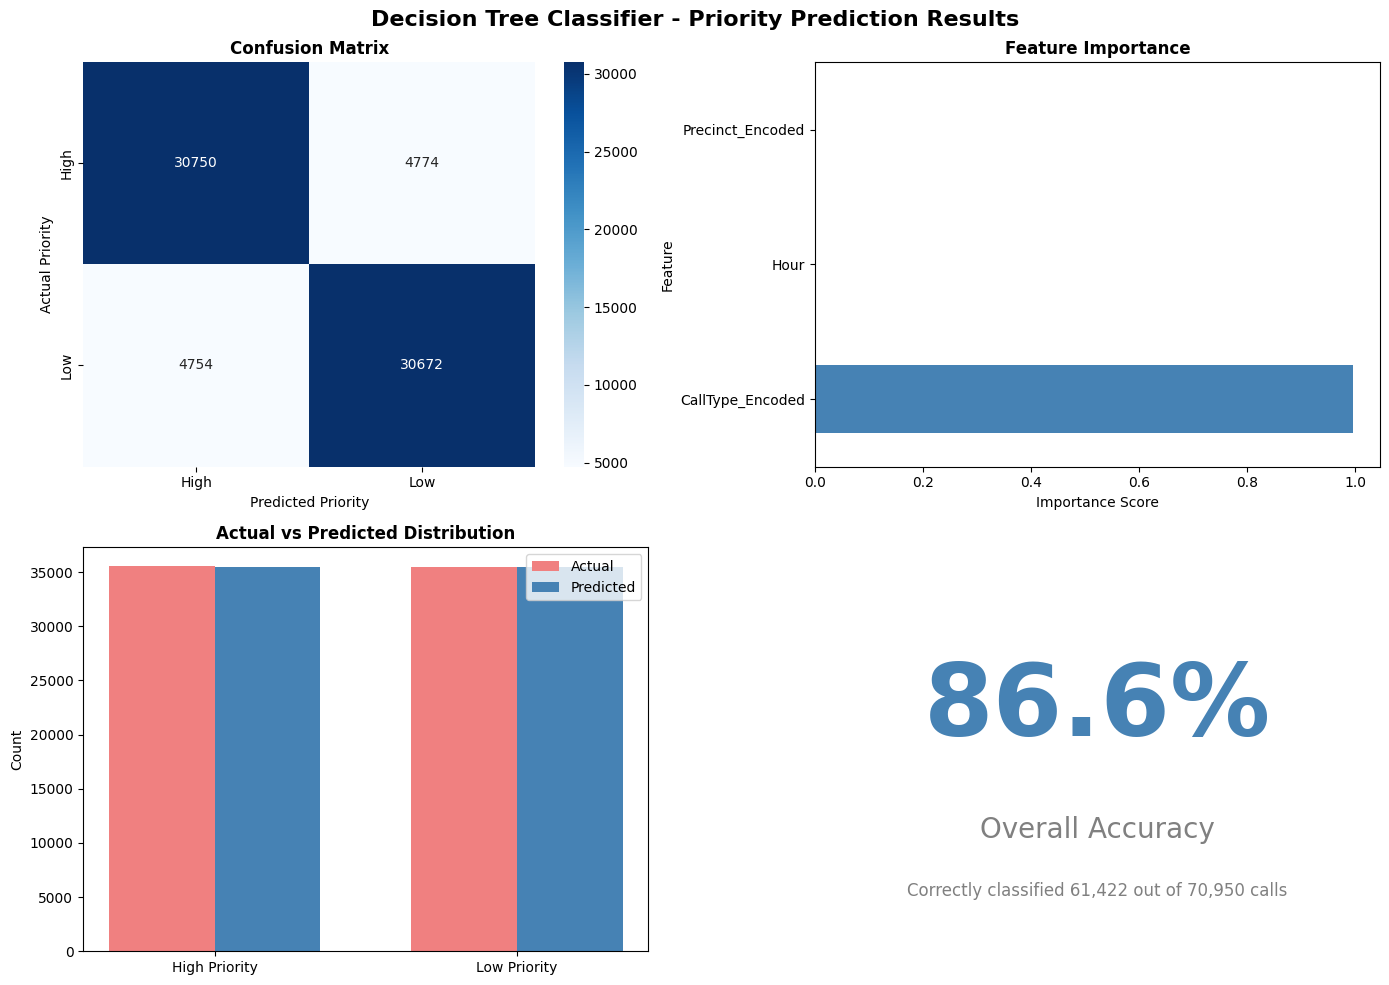


MODEL SUMMARY
Model Type: Decision Tree Classifier
Target Variable: Priority (High vs Low)
Training Data: 283,800 records
Testing Data: 70,950 records
Overall Accuracy: 86.57%
Most Important Feature: CallType_Encoded
Feature Importance: 0.996

✅ Analysis Complete!
📊 Results saved to 'priority_prediction_results.png'

Next Steps:
1. Review the visualization PNG file
2. Add results to your presentation
3. Compare with Random Forest model results


In [3]:
# ============================================================================
# Seattle 911 Call Data - Priority Prediction Model
# Model: Decision Tree Classifier
# Author: Dev Panchal
# Purpose: Predict whether a 911 call will be High or Low priority
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

print("=" * 80)
print("SEATTLE 911 CAD DATA - PRIORITY CLASSIFICATION MODEL")
print("=" * 80)

# ============================================================================
# STEP 1: LOAD DATA
# ============================================================================
print("\n[STEP 1] Loading Seattle 911 CAD Data...")

# Load data in chunks because file is large (5.5 GB)
# Adjust the file path to where your CSV is located
file_path = 'Seattle_911_CallData.csv'  # UPDATE THIS PATH!

# Load a sample for faster processing
# If you want to use full data, remove nrows parameter
df = pd.read_csv(file_path, nrows=500000)  # Using 500K rows for speed

print(f"✓ Loaded {len(df):,} records")
print(f"✓ Columns: {list(df.columns)}")

# ============================================================================
# STEP 2: DATA CLEANING & PREPARATION
# ============================================================================
print("\n[STEP 2] Cleaning and Preparing Data...")

# Select relevant columns
columns_needed = [
    'Initial Call Type',
    'Priority', 
    'Dispatch Precinct',
    'CAD Event Original Time Queued'
]

# Keep only needed columns
df_clean = df[columns_needed].copy()

# Remove rows with missing values
df_clean = df_clean.dropna()

# Extract hour from timestamp
df_clean['CAD Event Original Time Queued'] = pd.to_datetime(
    df_clean['CAD Event Original Time Queued'], 
    errors='coerce'
)
df_clean['Hour'] = df_clean['CAD Event Original Time Queued'].dt.hour

# Remove rows where time extraction failed
df_clean = df_clean.dropna(subset=['Hour'])

# Create binary target variable: High Priority (1-2) vs Low Priority (3-5)
df_clean['Priority_Binary'] = df_clean['Priority'].apply(
    lambda x: 'High' if x in [1, 2] else 'Low'
)

print(f"✓ Cleaned data: {len(df_clean):,} records")
print(f"\nPriority Distribution:")
print(df_clean['Priority_Binary'].value_counts())

# ============================================================================
# STEP 3: FEATURE ENGINEERING
# ============================================================================
print("\n[STEP 3] Creating Features...")

# Encode categorical variables
le_calltype = LabelEncoder()
le_precinct = LabelEncoder()

df_clean['CallType_Encoded'] = le_calltype.fit_transform(df_clean['Initial Call Type'])
df_clean['Precinct_Encoded'] = le_precinct.fit_transform(df_clean['Dispatch Precinct'])

# Create features matrix (X) and target (y)
features = ['CallType_Encoded', 'Precinct_Encoded', 'Hour']
X = df_clean[features]
y = df_clean['Priority_Binary']

print(f"✓ Features created: {features}")
print(f"✓ Feature matrix shape: {X.shape}")

# ============================================================================
# STEP 4: TRAIN/TEST SPLIT
# ============================================================================
print("\n[STEP 4] Splitting Data into Train/Test Sets...")

# 80% train, 20% test (same as Random Forest model)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42,
    stratify=y
)

print(f"✓ Training set: {len(X_train):,} records")
print(f"✓ Testing set: {len(X_test):,} records")

# ============================================================================
# STEP 5: BUILD DECISION TREE MODEL
# ============================================================================
print("\n[STEP 5] Training Decision Tree Classifier...")

# Create and train the model
model = DecisionTreeClassifier(
    max_depth=10,           # Prevent overfitting
    min_samples_split=100,  # Minimum samples to split a node
    min_samples_leaf=50,    # Minimum samples in a leaf
    random_state=42
)

model.fit(X_train, y_train)

print("✓ Model training complete!")

# ============================================================================
# STEP 6: MAKE PREDICTIONS
# ============================================================================
print("\n[STEP 6] Making Predictions on Test Set...")

y_pred = model.predict(X_test)

print("✓ Predictions generated")

# ============================================================================
# STEP 7: EVALUATE MODEL PERFORMANCE
# ============================================================================
print("\n[STEP 7] Evaluating Model Performance...")
print("=" * 80)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\n📊 MODEL ACCURACY: {accuracy:.2%}")
print("=" * 80)

# Classification report
print("\n📋 CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\n📊 CONFUSION MATRIX:")
print(cm)

# ============================================================================
# STEP 8: FEATURE IMPORTANCE
# ============================================================================
print("\n[STEP 8] Analyzing Feature Importance...")

# Get feature importances
importances = model.feature_importances_
feature_names = features

# Create DataFrame for better visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

print("\n📊 FEATURE IMPORTANCE:")
print(importance_df)

# ============================================================================
# STEP 9: VISUALIZATIONS
# ============================================================================
print("\n[STEP 9] Creating Visualizations...")

# Set style
plt.style.use('default')
sns.set_palette("husl")

# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Decision Tree Classifier - Priority Prediction Results', 
             fontsize=16, fontweight='bold')

# 1. Confusion Matrix Heatmap
ax1 = axes[0, 0]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1, 
            xticklabels=['High', 'Low'], yticklabels=['High', 'Low'])
ax1.set_title('Confusion Matrix', fontweight='bold')
ax1.set_ylabel('Actual Priority')
ax1.set_xlabel('Predicted Priority')

# 2. Feature Importance Bar Chart
ax2 = axes[0, 1]
importance_df.plot(kind='barh', x='Feature', y='Importance', ax=ax2, 
                   legend=False, color='steelblue')
ax2.set_title('Feature Importance', fontweight='bold')
ax2.set_xlabel('Importance Score')
ax2.set_ylabel('Feature')

# 3. Actual vs Predicted Distribution
ax3 = axes[1, 0]
actual_counts = y_test.value_counts()
pred_counts = pd.Series(y_pred).value_counts()
x_labels = ['High Priority', 'Low Priority']
x = np.arange(len(x_labels))
width = 0.35
ax3.bar(x - width/2, actual_counts, width, label='Actual', color='lightcoral')
ax3.bar(x + width/2, pred_counts, width, label='Predicted', color='steelblue')
ax3.set_title('Actual vs Predicted Distribution', fontweight='bold')
ax3.set_ylabel('Count')
ax3.set_xticks(x)
ax3.set_xticklabels(x_labels)
ax3.legend()

# 4. Model Accuracy Display
ax4 = axes[1, 1]
ax4.text(0.5, 0.6, f'{accuracy:.1%}', 
         ha='center', va='center', fontsize=72, fontweight='bold', 
         color='steelblue')
ax4.text(0.5, 0.3, 'Overall Accuracy', 
         ha='center', va='center', fontsize=20, color='gray')
ax4.text(0.5, 0.15, f'Correctly classified {int(accuracy * len(y_test)):,} out of {len(y_test):,} calls', 
         ha='center', va='center', fontsize=12, color='gray')
ax4.axis('off')

plt.tight_layout()
plt.savefig('priority_prediction_results.png', dpi=300, bbox_inches='tight')
print("✓ Saved visualization as 'priority_prediction_results.png'")

plt.show()

# ============================================================================
# STEP 10: SUMMARY STATISTICS
# ============================================================================
print("\n" + "=" * 80)
print("MODEL SUMMARY")
print("=" * 80)
print(f"Model Type: Decision Tree Classifier")
print(f"Target Variable: Priority (High vs Low)")
print(f"Training Data: {len(X_train):,} records")
print(f"Testing Data: {len(X_test):,} records")
print(f"Overall Accuracy: {accuracy:.2%}")
print(f"Most Important Feature: {importance_df.iloc[0]['Feature']}")
print(f"Feature Importance: {importance_df.iloc[0]['Importance']:.3f}")
print("=" * 80)

print("\n✅ Analysis Complete!")
print("📊 Results saved to 'priority_prediction_results.png'")
print("\nNext Steps:")
print("1. Review the visualization PNG file")
print("2. Add results to your presentation")
print("3. Compare with Random Forest model results")